# Volatilité des marchés financiers et annonces des banques centrales (2000-2025)

**Projet Python pour la data science, ENSAE 2A, 2026-2027**
**Auteurs :** Romain Mirat, Alexandre Lim de Montgolfier, Albéric Pungier

---

## Sommaire

* **Introduction et données**
* **Partie A, marchés et transmission** (`src/marches.py`, `src/transmission.py`) : niveaux de volatilité, corrélations, correction de Forbes et Rigobon
* **Partie B, la Fed** (`src/fed.py`) : effet des réunions du FOMC sur le S&P 500, le CAC 40 et le Nikkei
* **Partie C, la BCE** (`src/bce.py`) : effet des décisions de la BCE sur les mêmes marchés
* **Partie D, asymétrie et robustesse** (`src/comparaison.py`) : la Fed pèse-t-elle plus sur l'Europe que la BCE sur les États-Unis ?
* **Limites et conclusion**


In [1]:
import warnings
warnings.filterwarnings("ignore")

from IPython.display import display
from src import bce, comparaison, fed, marches, transmission

# Introduction et données

## La question

Quand la Fed ou la BCE annoncent une décision de taux, la volatilité boursière monte-t-elle, et ce choc se transmet-il aux autres places financières ? Nous traitons trois questions, de la plus locale à la plus large :

1. **Effet local.** La volatilité d'un marché monte-t-elle autour des décisions de sa banque centrale, par rapport à des jours témoins ?
2. **Transmission.** Le choc passe-t-il à l'Europe, à l'Asie ou aux États-Unis, et avec quel décalage ?
3. **Asymétrie.** La Fed pèse-t-elle plus sur l'Europe que la BCE sur les États-Unis ?

Nous gardons trois indices actions, le **S&P 500**, le **CAC 40** et le **Nikkei 225**, ainsi que le **VIX**, sur la période 2000-2025.

## Les données

| Source | Contenu | Accès |
|---|---|---|
| Yahoo Finance (`yfinance`) | Prix quotidiens (ouverture, plus haut, plus bas, clôture) des 4 indices | API non officielle, copie versionnée dans `data/raw/` |
| Site de la Fed | Dates des réunions du FOMC : page du calendrier (2021-2025) et une page d'archive par année (2000-2020) | Scraping |
| Site de la BCE | Dates des décisions de politique monétaire, une page par année | Scraping |
| FRED (Fed de Saint-Louis) | Taux directeur de la Fed | API |
| ECB Data Portal | Taux de dépôt de la BCE | API |

Les calendriers d'annonces (`data/annonces_fed.csv`, `data/annonces_bce.csv`) et les prix sont versionnés dans le dépôt : le rapport ne dépend donc pas de la disponibilité des sites au moment de l'exécution. Les fonctions `construire_annonces()` de `fed.py` et de `bce.py` refont toute la collecte.

Nos choix de nettoyage :

* **Les jours fériés ne sont pas comblés.** Chaque place a son calendrier. Nous alignons les marchés par séance et non par date, sans inventer de prix.
* **Les séances où le plus haut égale le plus bas** (2 sur 26 ans) sont écartées, car leur volatilité de Parkinson est nulle et son logarithme infini.
* **La BCE :** ses pages mêlent décisions, déclarations et comptes rendus. Nous gardons les communiqués intitulés « Monetary policy decisions », soit 293 dates.
* **La Fed :** nous retenons 207 réunions prévues. Sur 27 réunions d'urgence, nous gardons les 7 où le taux a changé, datées du jour de l'annonce et non de l'entrée en vigueur donnée par FRED.

## Le jour de réaction

Un marché ne peut réagir que s'il est ouvert. Le jour de réaction dépend donc de l'heure de l'annonce, en heure de Paris :

| Annonce | S&P 500 | CAC 40 | Nikkei |
|---|---|---|---|
| Fed, vers 20h | jour J | séance suivante | séance suivante |
| BCE, 13h45 puis 14h15 | jour J | jour J | séance suivante |

## La méthode

Nous mesurons la volatilité d'une séance avec l'estimateur de Parkinson, qui utilise le plus haut $H$ et le plus bas $L$ :

$$\hat\sigma_t = \sqrt{\frac{\left(\ln H_t - \ln L_t\right)^2}{4\ln 2}}$$

La **volatilité anormale** est le logarithme de ce chiffre moins sa moyenne sur les 20 séances précédentes : $a_t = \ln\hat\sigma_t - \frac{1}{20}\sum_{k=1}^{20}\ln\hat\sigma_{t-k}$. Elle vaut 0 un jour normal.

Pour chaque annonce, nous comparons la volatilité anormale de J-5 à J+5 à celle de **jours témoins** : les séances du même jour de la semaine, à plus d'une séance de toute annonce. Le **ratio** affiché est $\exp(\bar a_{\text{annonces}} - \bar a_{\text{témoins}})$ : 1,20 signifie une volatilité typique 20 % plus élevée que celle des témoins. La p-value vient d'un test de Mann-Whitney, qui ne suppose pas de loi normale. L'estimateur de Garman-Klass sert de contrôle.


# Partie A — Dynamique des marchés financiers, volatilité et transmission internationale

## 1. Caractérisation statistique et volatilité des grands marchés mondiaux

### Données et méthodologie
L'étude couvre la période du 1er janvier 2000 au 31 décembre 2025 pour trois grands indices boursiers représentatifs des principales zones horaires mondiales — le **S&P 500** (New York), le **CAC 40** (Paris) et le **Nikkei 225** (Tokyo) — ainsi que l'indice **VIX**, qui mesure la volatilité implicite à 30 jours anticipée sur les options du S&P 500.

À partir des rendements logarithmiques journaliers $r_t = \ln(C_t / C_{t-1})$ et des cotations intrajournalières (ouverture, plus haut, plus bas, clôture), nous estimons la volatilité réalisée journalière à l'aide de deux estimateurs basés sur l'amplitude des prix :
* **L'estimateur de Parkinson (1980)**, fondé sur l'écart extrême entre le plus haut ($H_t$) et le plus bas ($L_t$) de la séance :
  $$\sigma_{\text{Parkinson}, t} = \sqrt{\frac{1}{4 \ln 2} \left(\ln \frac{H_t}{L_t}\right)^2}$$
* **L'estimateur de Garman-Klass (1980)**, utilisé comme contrôle de robustesse en intégrant également l'écart entre ouverture et clôture :
  $$\sigma_{\text{GK}, t} = \sqrt{0,5 \left(\ln \frac{H_t}{L_t}\right)^2 - (2 \ln 2 - 1) \left(\ln \frac{C_t}{O_t}\right)^2}$$

### Faits stylisés des rendements et de la volatilité
L'analyse descriptive met en évidence les propriétés classiques des séries financières :
* **Queues épaisses (*leptokurticité*) et asymétrie négative :** tous les indices actions présentent une asymétrie (*skewness*) négative (entre $-0,22$ pour le CAC 40 et $-0,41$ pour le Nikkei) et un excès de kurtosis très élevé ($10,63$ pour le S&P 500, $7,24$ pour le Nikkei et $6,65$ pour le CAC 40), traduisant une fréquence des krachs extrêmes bien supérieure à celle d'une loi normale. Les pires séances atteignent $-12,77\%$ sur le S&P 500 (16 mars 2020), $-13,10\%$ sur le CAC 40 (12 mars 2020) et $-13,23\%$ sur le Nikkei (5 août 2024).
* **Cohérence des estimateurs de volatilité :** la volatilité moyenne de Parkinson s'établit à $0,78\%$ par jour sur le S&P 500, $0,80\%$ sur le Nikkei et $0,89\%$ sur le CAC 40. Elle est très fortement corrélée à l'estimateur de Garman-Klass ($r > 0,93$ sur l'ensemble des indices), confirmant la robustesse de la mesure.
* **Regroupement de la volatilité (*volatility clustering*) :** les épisodes de forte turbulence surviennent simultanément sur les trois places financières, notamment lors de la crise financière de 2008–2009 (volatilité lissée sur 20 jours culminant à $4,30\%$ sur le S&P 500, $3,97\%$ sur le Nikkei et $3,40\%$ sur le CAC 40, avec un VIX au-dessus de 80) et du krach du Covid-19 en mars 2020 ($3,26\%$, $2,63\%$ et $3,11\%$ respectivement, avec un VIX supérieur à 80). Le resserrement monétaire de 2022 génère une tension plus modérée mais persistante sur l'ensemble de l'année.
* **Renforcement apparent des corrélations en crise :** la corrélation contemporaine entre le S&P 500 et le CAC 40 passe de $0,49$ avant crise (2000–2007) à $0,59$ en 2008–2009 et $0,75$ au printemps 2020, tandis que le VIX demeure fortement corrélé négativement au S&P 500 (jusqu'à $-0,86$ en 2008–2009). En revanche, la corrélation le même jour entre le S&P 500 et le Nikkei reste faible ($0,11$ à $0,37$) en raison du décalage horaire entre Tokyo et New York.

,rendement_moyen_pct,ecart_type_pct,skewness,kurtosis,q01_pct,q99_pct,pire_journee,meilleure_journee,vol_parkinson_moy_pct,vol_gk_moy_pct,corr_parkinson_gk
marche,,,,,,,,,,,
SP500,0.0237,1.222,-0.35,10.63,-3.48,3.30,-12.77% (2020-03-16),+10.96% (2008-10-13),0.777,0.740,0.9382
CAC40,0.0048,1.374,-0.22,6.65,-4.04,3.52,-13.10% (2020-03-12),+10.59% (2008-10-13),0.893,0.889,0.9508
NIKKEI,0.0153,1.463,-0.41,7.24,-4.02,3.53,-13.23% (2024-08-05),+13.23% (2008-10-14),0.798,0.773,0.9349
VIX,-0.0074,7.157,1.02,6.88,-16.69,21.62,-44.24% (2025-04-09),+76.82% (2018-02-05),5.173,5.156,0.9539


(<Figure size 1200x700 with 2 Axes>, <Figure size 1500x400 with 5 Axes>)

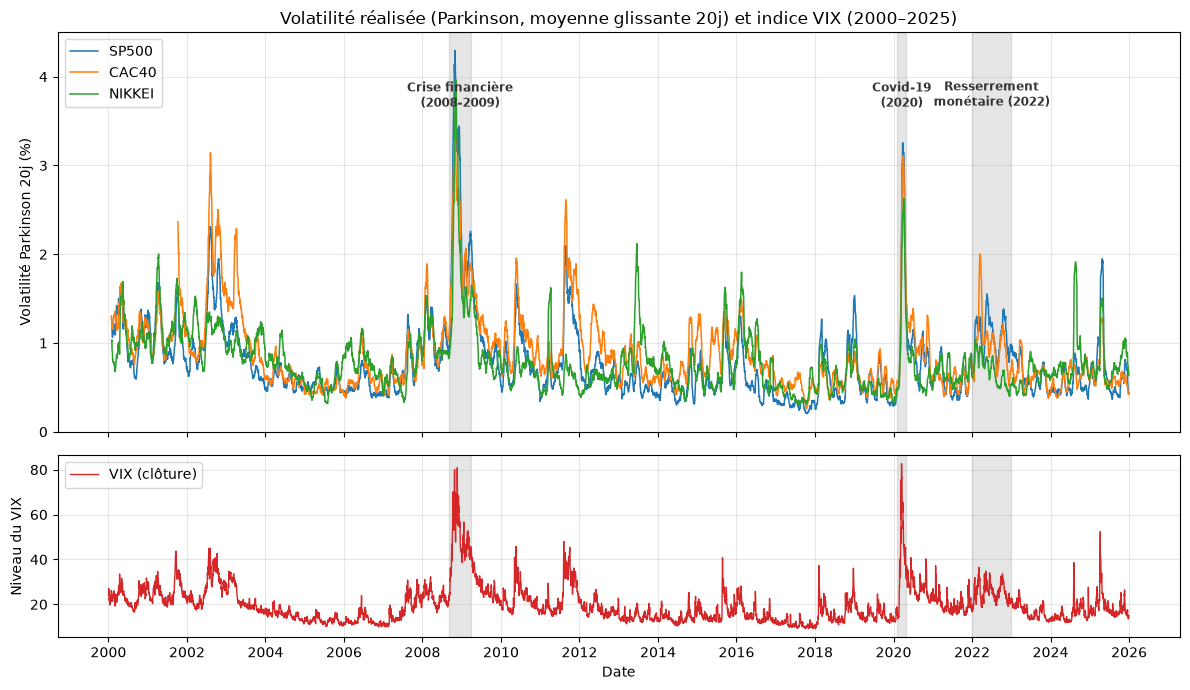

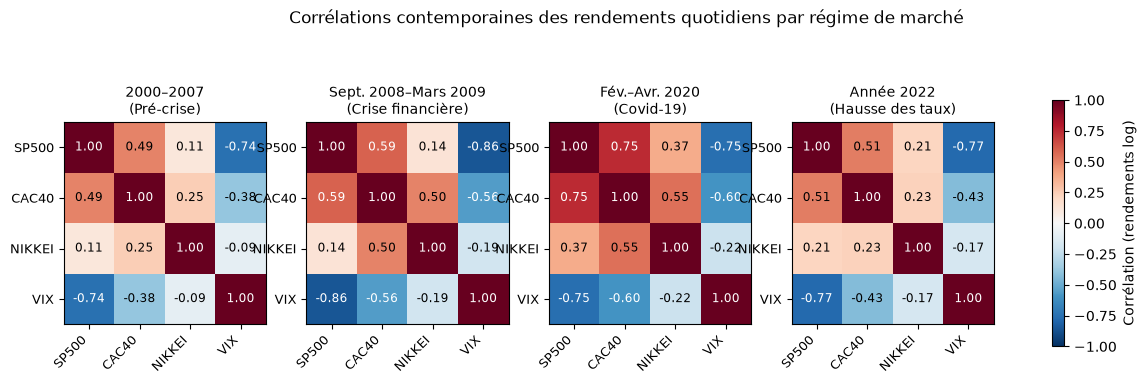

In [2]:
res_marches = marches.analyse()
display(res_marches)
marches.figure()

## 2. Transmission internationale des chocs et contagion financière

Au-delà de la dynamique propre à chaque indice, l'analyse des corrélations croisées met en évidence la hiérarchie temporelle et la forte interdépendance des places financières mondiales entre New York, Paris et Tokyo :

* **Effet de décalage horaire (*lead-lag* New York $\to$ Tokyo / Paris) :** Le chevauchement des horaires de cotation structure directement la diffusion des chocs. Le CAC 40, qui partage une partie de sa séance avec Wall Street, présente une corrélation contemporaine élevée avec le S&P 500 ($r_t = 0{,}5599$), contre $r_{t+1} = 0{,}2225$ le lendemain ($\beta_{t+1} = 0{,}2500$, $R^2 = 4{,}95\,\%$, mais $R^2 = 14{,}51\,\%$ sur le rendement *overnight* à l'ouverture). À l'inverse, Tokyo étant fermé pendant la séance américaine, le Nikkei 225 affiche une corrélation faible le jour même ($r_t = 0{,}1465$) mais absorbe massivement le choc américain dès le lendemain ($r_{t+1} = 0{,}4793$, $\beta_{t+1} = 0{,}5722$, $p < 10^{-70}$), le S&P 500 expliquant $22{,}97\,\%$ de la variance journalière et $43{,}61\,\%$ du rendement *overnight* de l'indice japonais.
* **Absence d'asymétrie établie entre baisses et hausses :** les séances négatives du S&P 500 semblent se transmettre un peu plus fortement que les séances positives, vers le CAC 40 ($\beta_{\text{baisses}} = 0{,}2850$ contre $\beta_{\text{hausses}} = 0{,}2117$) comme vers le Nikkei 225 ($0{,}6014$ contre $0{,}5258$). Ces écarts ne sont toutefois pas significatifs une fois les erreurs standard rendues robustes à l'hétéroscédasticité, très marquée sur les rendements financiers ($t = 0{,}95$, $p = 0{,}34$ pour le CAC 40 ; $t = 0{,}97$, $p = 0{,}33$ pour le Nikkei). Nous ne concluons donc pas à une transmission plus forte des baisses.
* **Correction du biais de volatilité (Forbes et Rigobon, 2002) :** En période de crise, la hausse brutale de la variance du S&P 500 (multipliée par un facteur allant de $3{,}78$ en 2022 à $27{,}17$ lors du choc Covid-19 de 2020) gonfle mécaniquement les corrélations brutes — qui grimpent par exemple de $0{,}5070$ en période calme (2003–2007, hors bulle Internet) à $0{,}5905$ (2008–2009) et $0{,}7480$ (2020) pour le CAC 40, ou de $0{,}4105$ à $0{,}6605$ (2008–2009) pour le Nikkei. Pour le CAC 40, la corrélation est mesurée le même jour : comme les séances de Paris et de New York se chevauchent, elle décrit un co-mouvement sans indiquer le sens de la transmission. Pour le Nikkei, elle relie le S&P 500 à la séance suivante de Tokyo. Une fois corrigées de ce biais d'hétéroscédasticité, les corrélations ajustées de Forbes-Rigobon retombent systématiquement en dessous de leur niveau de période calme (entre $0{,}0631$ et $0{,}3763$ selon les crises et les indices). La hausse apparente des co-mouvements en crise reflète donc avant tout l'ampleur des chocs globaux et l'interdépendance structurelle des marchés plutôt qu'une véritable contagion.

,corr_meme_jour_t,corr_lendemain_t1,beta_close_t1,p_val_close_t1,r2_close_t1_pct,beta_overnight_t1,r2_overnight_t1_pct
marche_cible,,,,,,,
CAC40,0.5599,0.2225,0.2500,2.590000e-73,4.95,0.2500,14.51
NIKKEI,0.1465,0.4793,0.5722,0.000000e+00,22.97,0.3992,43.61


,beta_baisses,corr_baisses,beta_hausses,corr_hausses,ecart_beta_b_moins_h,t_stat_asymetrie,p_valeur_asymetrie
marche_cible,,,,,,,
CAC40,0.2850,0.1908,0.2117,0.1442,0.0733,0.95,0.3428
NIKKEI,0.6014,0.3983,0.5258,0.3513,0.0755,0.97,0.3307


,paire,periode_crise,ratio_variance,corr_calme,corr_brute_crise,corr_forbes_rigobon,ecart_fr_vs_calme
0,SP500 -> CAC40,Crise financière (2008-2009),20.70,0.5070,0.5905,0.1588,-0.3482
1,SP500 -> CAC40,Covid-19 (Fév.-Avr. 2020),25.85,0.5070,0.7480,0.2164,-0.2906
2,SP500 -> CAC40,Resserrement monétaire (2022),3.87,0.5070,0.5124,0.2902,-0.2168
3,SP500 -> NIKKEI_t1,Crise financière (2008-2009),21.03,0.4105,0.6605,0.1884,-0.2221
4,SP500 -> NIKKEI_t1,Covid-19 (Fév.-Avr. 2020),27.17,0.4105,0.3128,0.0631,-0.3474
5,SP500 -> NIKKEI_t1,Resserrement monétaire (2022),3.78,0.4105,0.6199,0.3763,-0.0342


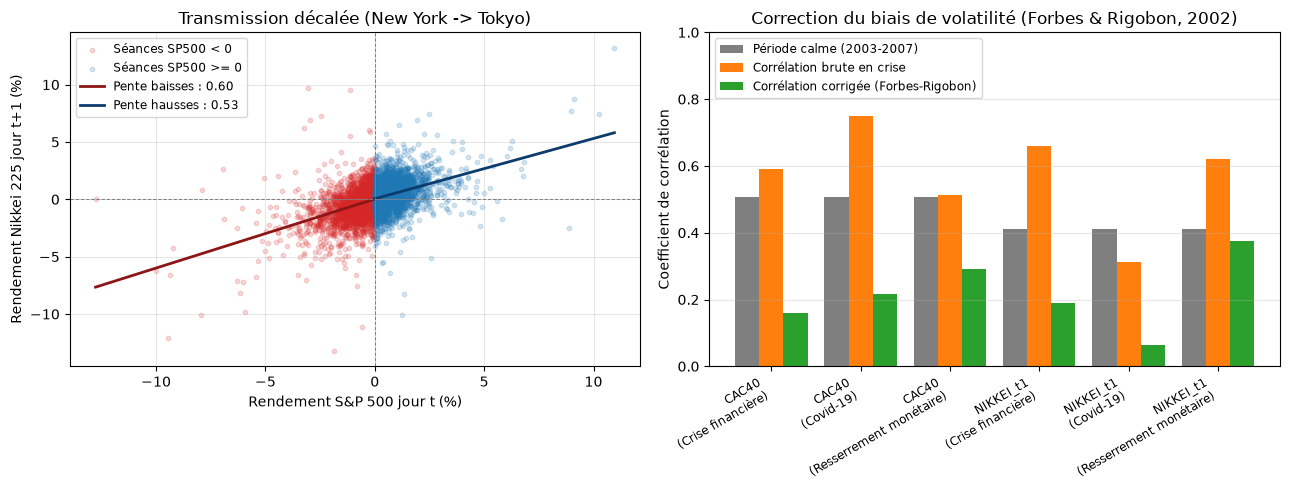

In [3]:
res_trans = transmission.analyse()
display(res_trans["decalage_horaire"])
display(res_trans["asymetrie"])
display(res_trans["forbes_rigobon"])
transmission.figure()

---

# Partie B - la Fed

## Effet des décisions de la Fed

### Les données

Nous avons récupéré les dates des décisions du FOMC de 2000 à 2025 par scraping du site de la Fed : la page du calendrier pour 2021-2025, et une page d'archive par année pour 2000-2020. Chaque réunion dure deux jours ; nous retenons le second, jour de l'annonce.

Nous obtenons 207 réunions prévues, soit 8 par an. Deux anomalies ont été traitées : un doublon en septembre 2003 (réunion comptée le 15 et le 16), et l'année 2020, qui n'en compte que 7 car la réunion de mars a été annulée et remplacée par deux réunions d'urgence au début du Covid.

Le taux directeur, téléchargé via l'API FRED, donne le sens de chaque décision : sur les 214 décisions retenues, 140 laissent le taux inchangé. Il sert aussi à trier les réunions d'urgence : sur 27, nous ne gardons que les 7 où le taux a réellement changé, comme le 17 septembre 2001 ou le 15 mars 2020. FRED date ces changements à leur entrée en vigueur : pour les deux urgences de mars 2020, nous retenons donc le jour de l'annonce, le 3 et le 15 mars.

### L'effet sur les marchés américains

La Fed annonce ses décisions à 14h à New York : le S&P 500 réagit donc le jour même. Ce jour-là, sa volatilité est 24 % plus forte que lors d'un jour témoin (ratio de 1,24, p-value inférieure à 0,001). L'effet est donc net et significatif.

Il dure environ deux jours : la volatilité reste élevée le lendemain (ratio de 1,16), puis revient à la normale. À l'inverse, la veille de l'annonce, elle est plus faible que d'habitude (ratio de 0,93) : les marchés attendent la décision.

Le VIX, qui mesure la volatilité attendue par les marchés, monte légèrement dans les jours qui précèdent l'annonce, puis baisse de 1,7 % le jour même. La décision semble lever une incertitude : les marchés s'agitent sur le moment, mais anticipent ensuite des semaines plus calmes.

### L'effet sur l'Europe et l'Asie

À 14h à New York, il est 20h à Paris et la nuit à Tokyo : le CAC 40 et le Nikkei sont fermés et ne peuvent réagir que le lendemain. Ce jour-là, la volatilité du CAC 40 est 13 % plus forte que lors d'un jour témoin (p-value inférieure à 0,001), et celle du Nikkei 10 % plus forte (p-value de 0,002).

Le choc se transmet donc bien hors des États-Unis, mais en s'atténuant : l'effet est environ deux fois plus faible en Europe et en Asie qu'à New York.

### Contrôle : réunions prévues et urgences

Les 7 décisions d'urgence sont des baisses de taux surprises, prises entre deux réunions, souvent en pleine crise. Comme leur heure varie, nous fixons le jour de réaction selon le moment de l'annonce : le CAC 40 réagit le jour même, sauf le 3 janvier 2001, où la Fed a annoncé sa baisse après la clôture de Paris. Leur effet est beaucoup plus fort : la volatilité fait plus que doubler le jour de la réaction sur le S&P 500 (ratio de 2,66) et sur le CAC 40 (2,41), contre 1,24 et 1,13 pour les réunions prévues. Elle augmente aussi sur le Nikkei (1,53, p-value de 0,006), contre 1,10 pour les réunions prévues. Ce contraste suggère que l'effet de surprise compte, sans le prouver, car ces décisions sont prises dans des périodes déjà très agitées.

### Limites

- Les données sont quotidiennes : on mesure l'effet au jour près, pas à la minute.
- Le jour d'une réunion, d'autres nouvelles peuvent aussi tomber : on ne prouve pas que l'annonce cause seule la volatilité. C'est particulièrement vrai pour les urgences, décidées en pleine crise (11 septembre 2001, Covid).
- Le sens de la décision ne mesure pas la surprise : la plupart des décisions sont anticipées par les marchés.
- Avec seulement 7 urgences, le contrôle reste fragile, même si les écarts sont significatifs.
- Les dates des réunions prévues de 2017 à 2025 coïncident avec le calendrier du FOMC utilisé en TD. Celles de 2000 à 2016 ont seulement été contrôlées par le nombre de réunions par an et par des vérifications manuelles.

,banque,marche,jour,ratio,p_value,n
4,Fed,SP500,-1,0.932,0.009,207
5,Fed,SP500,0,1.241,0.000,207
6,Fed,SP500,1,1.163,0.000,207
7,Fed,SP500,2,1.041,0.334,207
15,Fed,CAC40,-1,0.903,0.000,207
16,Fed,CAC40,0,1.128,0.000,207
17,Fed,CAC40,1,1.050,0.133,207
18,Fed,CAC40,2,1.026,0.477,207
26,Fed,NIKKEI,-1,0.949,0.043,207
27,Fed,NIKKEI,0,1.098,0.002,207


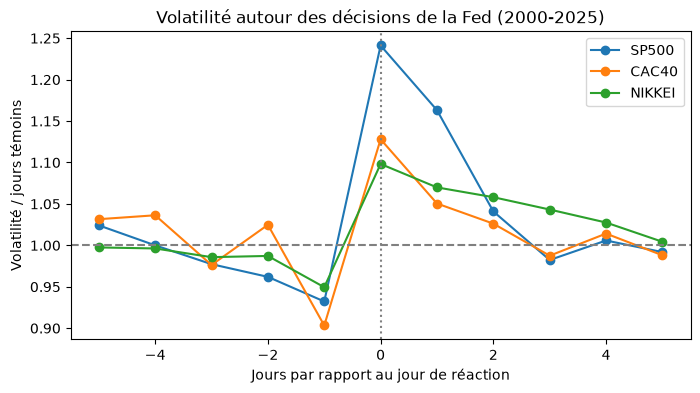

In [4]:
res_fed = fed.analyse()
display(res_fed[res_fed["jour"].between(-1, 2)].round(3))
fig_fed = fed.figure(res_fed)

In [5]:
res_urgences = fed.analyse_urgences()
display(res_urgences[res_urgences["jour"] == 0].round(3))

,banque,marche,jour,ratio,p_value,n
5,Fed,SP500,0,2.664,0.000,7
16,Fed,CAC40,0,2.414,0.000,7
27,Fed,NIKKEI,0,1.528,0.006,7


---

# Partie C — La BCE

## Effet des décisions de la BCE

### Les données

Nous avons reconstruit le calendrier des décisions de la BCE à partir de ses pages annuelles de politique monétaire, de 2000 à 2025. Comme ces pages mêlent les décisions, les déclarations et les comptes rendus de réunion, nous n'avons gardé que les communiqués intitulés « Monetary policy decisions », ce qui donne 293 dates. Leur rythme varie au cours de la période, puisqu'on compte deux décisions par mois en 2000 et 2001, environ une par mois de 2002 à 2014, puis huit par an depuis 2015.

Nous avons ensuite ajouté la variation du taux de dépôt, tirée de l'API de la BCE. Cette série date chaque changement à son entrée en vigueur, souvent six jours après la décision, si bien que nous attribuons chaque changement à la dernière décision qui le précède. Le 8 octobre 2008 demande un traitement particulier, car le taux de dépôt baisse de 0,50 point ce jour-là puis remonte de 0,50 point le lendemain, lorsque la BCE resserre l'écart entre ses taux. Nous retenons la baisse, sans quoi cette décision d'urgence apparaîtrait comme une absence de changement. Au total, 56 décisions modifient le taux de dépôt et trois autres baissent uniquement le taux principal, le 7 mai 2009, le 2 mai 2013 et le 7 novembre 2013. Nous comptons ces 59 décisions comme des changements de taux. Deux réunions se sont tenues hors calendrier, le 17 septembre 2001 et le 8 octobre 2008.

Le jour de réaction dépend de l'heure de l'annonce. La BCE publie ses décisions à 13h45, puis à 14h15 depuis juillet 2022, donc pendant la séance de Paris et avant l'ouverture de New York. Nous mesurons par conséquent la réaction du CAC 40 et du S&P 500 le jour même. Comme la Bourse de Tokyo est déjà fermée à cette heure, nous regardons le Nikkei à la séance suivante.

### L'effet sur le CAC 40

Le jour de la décision, la volatilité du CAC 40 dépasse de 18 % celle des jours témoins, pris le même jour de la semaine (ratio de 1,18, p < 0,001). Elle reste supérieure de 6 % le lendemain (p = 0,011), puis passe 5 % sous son niveau habituel deux séances après la décision (p = 0,022). Seul l'effet du jour même reste significatif après une correction de Bonferroni sur les 33 tests de la figure.

La hausse est plus forte quand la BCE modifie ses taux, puisqu'elle atteint 39 % pour les 59 décisions avec changement contre 13 % pour les 234 décisions sans changement, et cet écart entre les deux groupes est significatif (p = 0,0005). Le marché réagit donc même lorsque les taux ne bougent pas, mais nos données quotidiennes ne permettent pas de dire si cette réaction vient du communiqué ou de la conférence de presse. Le résultat ne dépend pas des réunions bimensuelles du début de la période, car le ratio reste à 1,21 lorsqu'on retire les années 2000 et 2001. Il ne dépend pas non plus de la mesure de volatilité, puisque l'estimateur de Garman-Klass, qui utilise aussi l'ouverture et la clôture, donne un ratio de 1,17.

### L'effet sur les États-Unis et l'Asie

Le S&P 500 ne réagit pas le jour de la décision, avec un ratio de 1,02 (p = 0,58), sur 292 séances parce que Wall Street était fermée le 13 septembre 2001. Ce constat ne dépend ni des années 2000 et 2001, dont le retrait laisse le ratio à 1,02 (p = 0,49), ni de la mesure de volatilité, puisque l'estimateur de Garman-Klass donne 1,01 (p = 0,94). L'écart entre les décisions avec changement (1,12) et sans changement (0,99) n'est pas non plus significatif (p = 0,07). Nous ne pouvons donc pas conclure à un effet de la BCE sur la volatilité américaine le jour de la décision.

Le Nikkei ne réagit pas non plus à la séance suivante, avec un ratio de 0,98 (p = 0,61), et ce constat vaut aussi bien pour les décisions avec changement que sans changement. La volatilité du S&P 500 est en revanche supérieure de 12 % le lendemain de la décision (p < 0,001), et le S&P 500 et le Nikkei présentent un pic plus modeste quatre séances après (ratios de 1,07 et 1,06). Nous ne les attribuons pas à la BCE, car la plupart de ses décisions tombent un jeudi : le lendemain est donc souvent le premier vendredi du mois, jour habituel du rapport américain sur l'emploi, et la quatrième séance suivante coïncide parfois avec la réaction de ces marchés à une décision de la Fed.

,banque,marche,jour,ratio,p_value,n
4,BCE,CAC40,-1,1.047,0.043,293
5,BCE,CAC40,0,1.179,0.000,293
6,BCE,CAC40,1,1.059,0.011,293
7,BCE,CAC40,2,0.950,0.022,293
15,BCE,SP500,-1,0.994,0.744,292
16,BCE,SP500,0,1.019,0.581,292
17,BCE,SP500,1,1.119,0.000,292
18,BCE,SP500,2,0.957,0.066,292
26,BCE,NIKKEI,-1,0.970,0.095,293
27,BCE,NIKKEI,0,0.984,0.610,293


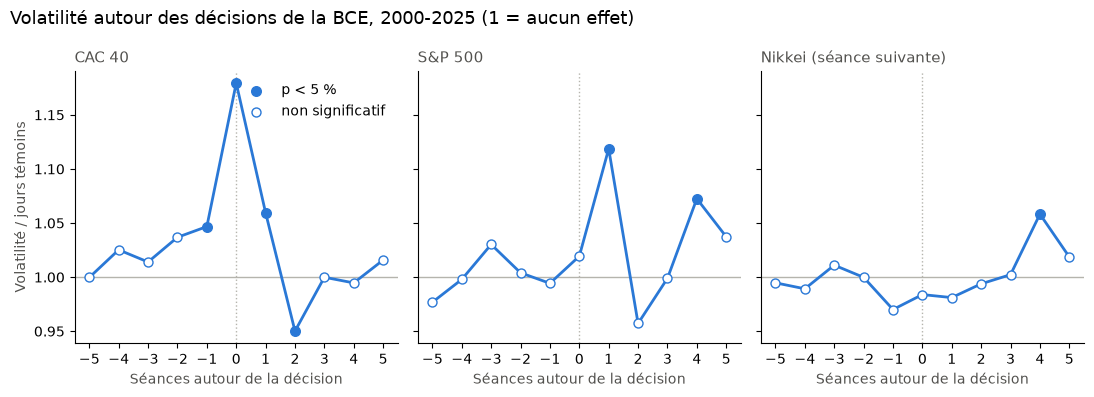

In [6]:
res_bce = bce.analyse()
display(res_bce[res_bce["jour"].between(-1, 2)].round(3))
fig_bce = bce.figure(res_bce)

In [7]:
display(bce.controle_changement().round(3))

,banque,marche,groupe,ratio,p_value,n,p_ecart
0,BCE,CAC40,avec changement,1.385,0.000,59,0.000
1,BCE,CAC40,sans changement,1.133,0.000,234,0.000
2,BCE,SP500,avec changement,1.123,0.065,59,0.072
3,BCE,SP500,sans changement,0.995,0.770,233,0.072
4,BCE,NIKKEI,avec changement,0.954,0.625,59,0.755
5,BCE,NIKKEI,sans changement,0.992,0.738,234,0.755


In [8]:
display(bce.controle_2002().round(3))
display(bce.controle_garman_klass().round(3))

,banque,marche,ratio,p_value,n
0,BCE,CAC40,1.207,0.000,245
1,BCE,SP500,1.023,0.487,245
2,BCE,NIKKEI,0.980,0.538,245


,banque,marche,ratio,p_value,n
0,BCE,CAC40,1.167,0.000,293
1,BCE,SP500,1.006,0.940,292
2,BCE,NIKKEI,0.980,0.403,293


# Partie D - Asymétrie et robustesse

La question 3 compare l'effet de la Fed sur l'Europe à celui de la BCE sur les États-Unis. Avant de la trancher, nous vérifions que l'effet d'une banque ne vient pas de l'autre : 27 réunions de la Fed tombent à un jour d'une décision de la BCE. Le contrôle retire ces réunions et, symétriquement, les 27 décisions de la BCE proches d'une réunion de la Fed. Il garde 180 réunions de la Fed sur 207 et 266 décisions de la BCE sur 293, et retire toutes les autres annonces des jours témoins (premier tableau ci-dessous).

**Les résultats principaux tiennent.** Chaque banque fait monter la volatilité de son marché (1,28 pour la Fed sur le S&P 500, 1,17 pour la BCE sur le CAC 40). La Fed laisse aussi un effet sur le CAC 40 (1,13) et sur le Nikkei (1,13) à la séance suivante. La BCE n'en laisse aucun sur le S&P 500 (1,02, p = 0,53) ni sur le Nikkei (0,99, p = 0,74).

Le second tableau compare directement les deux effets entre continents : celui de la Fed sur le CAC 40 et celui de la BCE sur le S&P 500. Le rapport est le quotient des deux ratios, et son intervalle de confiance à 95 % utilise l'approximation normale.

**La Fed pèse plus sur l'Europe que la BCE sur les États-Unis, mais l'écart est modeste.** La volatilité du CAC 40 monte de 12,5 % après une réunion de la Fed, celle du S&P 500 de 2,4 % après une décision de la BCE. Le rapport des deux effets vaut 1,10 et son intervalle de confiance, de 1,01 à 1,19, exclut 1 de justesse. Deux précautions : les horaires diffèrent (la Fed annonce après la clôture de Paris, la BCE pendant la séance de New York) et les deux échantillons n'ont pas la même taille, 180 réunions contre 265 décisions.


In [9]:
display(comparaison.controle_reunions_proches().round(3))

,banque,marche,ratio,p_value,n
0,Fed,SP500,1.278,0.000,180
1,Fed,CAC40,1.125,0.000,180
2,Fed,NIKKEI,1.128,0.000,180
3,BCE,CAC40,1.173,0.000,266
4,BCE,SP500,1.024,0.525,265
5,BCE,NIKKEI,0.991,0.744,266


In [10]:
display(comparaison.analyse_asymetrie().round(3))

,fed_vers_cac40,bce_vers_sp500,rapport,ic95_bas,ic95_haut,n_fed,n_bce
0,1.125,1.024,1.098,1.013,1.191,180,265


# Limites

* **Des données quotidiennes.** Nous mesurons l'effet au jour près, pas à la minute. Pour la Fed, la conférence de presse tombe le même jour que le communiqué à certaines réunions depuis 2011 et à toutes depuis 2019 : nous ne pouvons pas séparer les deux.
* **D'autres nouvelles le même jour.** Une annonce peut coïncider avec une autre information. C'est probable pour l'effet de la BCE sur le S&P 500 le lendemain de la décision, qui tombe souvent un premier vendredi du mois, jour habituel du rapport américain sur l'emploi. C'est aussi vrai du pic à quatre séances de la décision de la BCE, qui coïncide parfois avec une réunion de la Fed. Ce sont des explications plausibles que nous n'avons pas testées.
* **Pas de mesure de la surprise.** Le sens de la décision ne dit pas si elle était attendue. Les 7 réunions d'urgence sont des surprises, mais prises en pleine crise (11 septembre 2001, crise de 2008, Covid) : leur effet très fort ne prouve pas que la surprise seule en est la cause.
* **Des tests qui se répètent.** La figure de la BCE contient 33 tests : seul l'effet du CAC 40 le jour même et celui du S&P 500 le lendemain passent la correction de Bonferroni. Les volatilités de séances voisines sont corrélées, ce qui rend les p-values proches de 5 % moins fiables.
* **Une comparaison Fed/BCE imparfaite.** Les horaires, les marchés et les tailles d'échantillon diffèrent entre les deux effets comparés.
* **La correction de Forbes et Rigobon** compare des crises à une période calme choisie (2003-2007). Pour le CAC 40, la corrélation est mesurée le même jour que le S&P 500, ce qui ne donne pas le sens de la transmission.
* **Les données.** `yfinance` n'est pas une API officielle, d'où la copie versionnée des prix. Les dates de la Fed pour 2000-2016 ont été contrôlées par le nombre de réunions par an, et non comparées à une source externe ; celles de 2017-2025 coïncident avec le calendrier du FOMC utilisé en TD. Le contrôle avec Garman-Klass n'a été fait que pour la BCE.


# Conclusion

**Question 1, effet local.** Chaque banque fait monter la volatilité de son marché le jour de la décision : +24 % pour la Fed sur le S&P 500 et +18 % pour la BCE sur le CAC 40, avec une p-value inférieure à 0,001 dans les deux cas. L'effet est plus fort quand la BCE modifie ses taux (+39 % contre +13 %) et bien plus fort pour les 7 réunions d'urgence de la Fed (ratio de 2,66 sur le S&P 500).

**Question 2, transmission.** Le choc de la Fed se transmet à l'Europe et à l'Asie en s'atténuant : +13 % sur le CAC 40 et +10 % sur le Nikkei à la séance suivante. Celui de la BCE ne passe pas : ni le S&P 500 ni le Nikkei ne réagissent le jour de la décision. Côté corrélations, la hausse observée en crise disparaît une fois corrigée du biais de Forbes et Rigobon : nos données ne permettent pas de parler de contagion, et une transmission plus forte des baisses que des hausses n'est pas établie.

**Question 3, asymétrie.** La Fed pèse plus sur l'Europe que la BCE sur les États-Unis : +12,5 % sur le CAC 40 contre +2,4 % sur le S&P 500, soit un rapport de 1,10 dont l'intervalle de confiance à 95 % va de 1,01 à 1,19. L'écart est réel mais étroit.

**En une phrase,** quand la Fed parle, les marchés européens et asiatiques bougent le lendemain, alors que quand la BCE parle, seul le marché européen bouge.

**Ouverture.** Le contenu des communiqués explique-t-il l'ampleur de la réaction ? Notre étude ne mesure que le jour et le sens des décisions. Répondre demanderait une vraie mesure du ton des textes, hors de portée de ce projet.
